<a href="https://colab.research.google.com/github/irgishalby/credit-fraud-detection/blob/main/credit_fraud.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Credit Card Fraud Detection

## Setup

In [ ]:
%pip install -q imbalanced-learn

In [ ]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score,
    average_precision_score, precision_recall_curve,
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from xgboost import XGBClassifier

## Data Loading

In [ ]:
file_path = "creditcard.csv"

df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "mlg-ulb/creditcardfraud",
  path = file_path
)

df.head()

/tmp/ipykernel_890/3074614125.py:3: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'creditcardfraud' dataset.


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


1. Time: Number of seconds elapsed between this transaction and the first transaction in the dataset


2. V1-V28: Result of a PCA Dimensionality reduction to protect user identities and sensitive features(V1-V28)

3. Amount: Transaction amount

4. Class: 1 for fraudulent transactions, 0 otherwise

## EDA

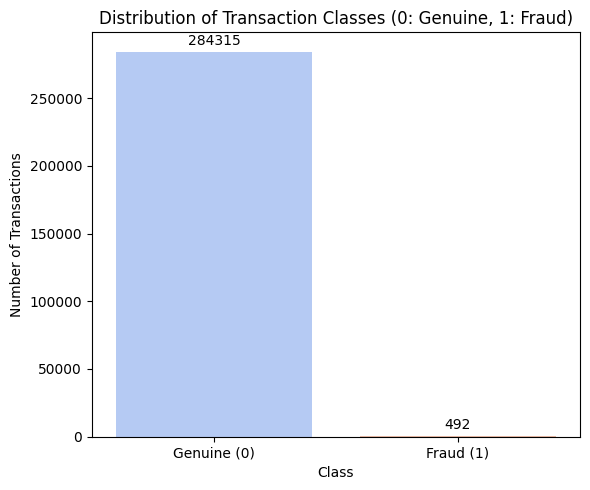

In [ ]:
class_counts = df['Class'].value_counts()

plt.figure(figsize=(6, 5))
sns.barplot(x=class_counts.index, y=class_counts.values, hue=class_counts.index, palette='coolwarm', legend=False)

plt.title('Distribution of Transaction Classes (0: Genuine, 1: Fraud)')
plt.xlabel('Class')
plt.ylabel('Number of Transactions')
plt.xticks(ticks=[0, 1], labels=['Genuine (0)', 'Fraud (1)'])

for i, count in enumerate(class_counts):
    plt.text(i, count + class_counts.max() * 0.01, f'{count}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

99.83% genuine, at least we know that good people still exist

Plan!
1. Scale time and amount (Models learn easier with smaller number, we need to scale it down so no feature dominates just because its numbers are bigger)
2. Do stratified train-test split
3. Train simple baseline (logistic regression)
4. Evaluate
5. Handle imbalance using SMOTE
6. Try stronger models



## Preprocessing

In [ ]:
# Split features and target
X = df.drop(columns=['Class'])
y = df['Class']

# Split the dataset into train and test sets first (using stratified split due to class imbalance)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Initialize RobustScaler
scaler = RobustScaler()

# Fit on training data and transform both training and testing sets
# Only 'Time' and 'Amount' need scaling; V1-V28 are already PCA-scaled.
scale_cols = ['Time', 'Amount']

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])

print("Training set shape:", X_train_scaled.shape)
print("Testing set shape:", X_test_scaled.shape)
print("\nFirst 5 rows of scaled training features (showing Time and Amount):")
print(X_train_scaled[scale_cols].head())

Training set shape: (227845, 30)
Testing set shape: (56962, 30)

First 5 rows of scaled training features (showing Time and Amount):
            Time    Amount
265518  0.905774 -0.204315
180305  0.465984 -0.264579
42664  -0.512286  2.130828
198723  0.561678 -0.221294
82325  -0.298886  0.892136


## Baseline: Logistic Regression

              precision    recall  f1-score   support

 Genuine (0)     0.9994    0.9998    0.9996     56864
   Fraud (1)     0.8289    0.6429    0.7241        98

    accuracy                         0.9992     56962
   macro avg     0.9142    0.8213    0.8619     56962
weighted avg     0.9991    0.9992    0.9991     56962

Confusion matrix:
 [[56851    13]
 [   35    63]]


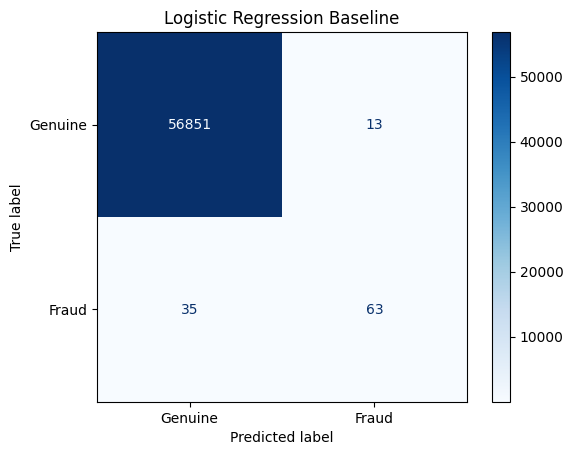

In [ ]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)

print(classification_report(y_test, y_pred, target_names=['Genuine (0)', 'Fraud (1)'], digits=4))

cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:\n", cm)

ConfusionMatrixDisplay(cm, display_labels=['Genuine', 'Fraud']).plot(cmap='Blues', values_format='d')
plt.title('Logistic Regression Baseline')
plt.show()

## SMOTE

Before SMOTE: {0: 227451, 1: 394}
After SMOTE:  {0: 227451, 1: 227451}


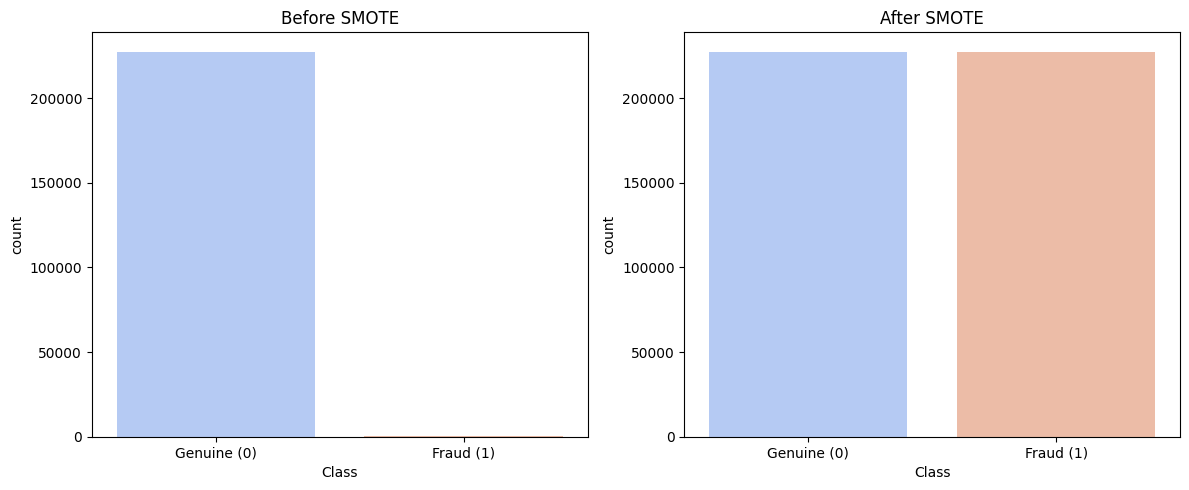

In [ ]:
# SMOTE on training data only, test set stays untouched
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE: ", y_train_res.value_counts().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(x=y_train, ax=axes[0], hue=y_train, palette='coolwarm', legend=False)
axes[0].set_title('Before SMOTE')
axes[0].set_xticks([0, 1], ['Genuine (0)', 'Fraud (1)'])
axes[0].set_xlabel('Class')

sns.countplot(x=y_train_res, ax=axes[1], hue=y_train_res, palette='coolwarm', legend=False)
axes[1].set_title('After SMOTE')
axes[1].set_xticks([0, 1], ['Genuine (0)', 'Fraud (1)'])
axes[1].set_xlabel('Class')

plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

 Genuine (0)     0.9999    0.9747    0.9871     56864
   Fraud (1)     0.0589    0.9184    0.1106        98

    accuracy                         0.9746     56962
   macro avg     0.5294    0.9465    0.5489     56962
weighted avg     0.9982    0.9746    0.9856     56962

Confusion matrix:
 [[55425  1439]
 [    8    90]]


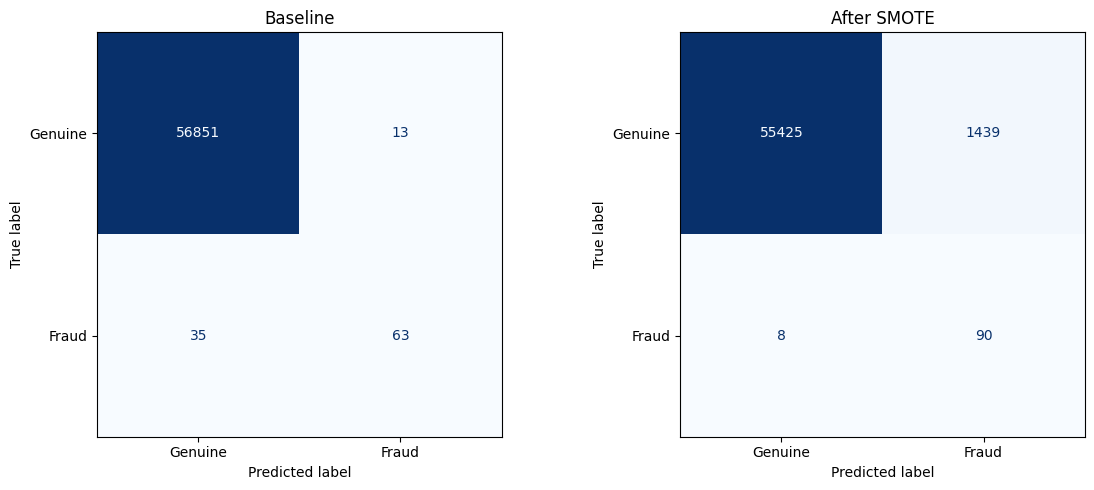

                   Baseline   SMOTE
Precision (fraud)    0.8289  0.0589
Recall (fraud)       0.6429  0.9184
F1 (fraud)           0.7241  0.1106


In [ ]:
log_reg_smote = LogisticRegression(max_iter=1000, random_state=42)
log_reg_smote.fit(X_train_res, y_train_res)

y_pred_smote = log_reg_smote.predict(X_test_scaled)

print(classification_report(y_test, y_pred_smote, target_names=['Genuine (0)', 'Fraud (1)'], digits=4))

cm_smote = confusion_matrix(y_test, y_pred_smote)
print("Confusion matrix:\n", cm_smote)

# Side-by-side confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(cm, display_labels=['Genuine', 'Fraud']).plot(ax=axes[0], cmap='Blues', values_format='d', colorbar=False)
axes[0].set_title('Baseline')
ConfusionMatrixDisplay(cm_smote, display_labels=['Genuine', 'Fraud']).plot(ax=axes[1], cmap='Blues', values_format='d', colorbar=False)
axes[1].set_title('After SMOTE')
plt.tight_layout()
plt.show()

# Fraud-class comparison
comparison = pd.DataFrame({
    'Baseline': [precision_score(y_test, y_pred), recall_score(y_test, y_pred), f1_score(y_test, y_pred)],
    'SMOTE':    [precision_score(y_test, y_pred_smote), recall_score(y_test, y_pred_smote), f1_score(y_test, y_pred_smote)],
}, index=['Precision (fraud)', 'Recall (fraud)', 'F1 (fraud)'])
print(comparison.round(4))

it did catch more but it also fitnah alot too, we can fix this by tuning threshold, hyperparameters, and using stronger models

## Model Tuning

1. Tune `C` with 5-fold stratified CV on the training set, scored by PR-AUC. SMOTE sits inside the pipeline so it only touches training folds. The search also tries no SMOTE.
2. Tune the decision threshold by F1, using out-of-fold probabilities on the training set.
3. Evaluate once on the untouched test set.

Best params: {'clf__C': 0.1, 'smote': 'passthrough'}
Best CV PR-AUC: 0.7622


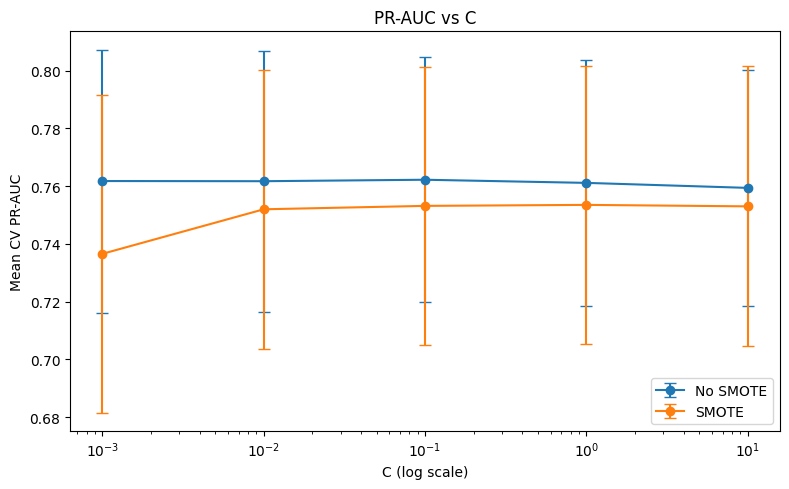

sampling      C  mean_test_score  std_test_score
No SMOTE  0.100           0.7622          0.0424
No SMOTE  0.001           0.7618          0.0456
No SMOTE  0.010           0.7617          0.0453
No SMOTE  1.000           0.7612          0.0427
No SMOTE 10.000           0.7594          0.0408
   SMOTE  1.000           0.7535          0.0482
   SMOTE  0.100           0.7532          0.0481
   SMOTE 10.000           0.7530          0.0485
   SMOTE  0.010           0.7520          0.0484
   SMOTE  0.001           0.7366          0.0551


In [ ]:
pipe = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('clf', LogisticRegression(max_iter=1000, random_state=42)),
])

param_grid = {
    'smote': [SMOTE(random_state=42), 'passthrough'],
    'clf__C': [0.001, 0.01, 0.1, 1, 10],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(pipe, param_grid, scoring='average_precision', cv=cv, n_jobs=-1)
grid.fit(X_train_scaled, y_train)

print("Best params:", grid.best_params_)
print("Best CV PR-AUC:", round(grid.best_score_, 4))

# PR-AUC per C, with and without SMOTE
results = pd.DataFrame(grid.cv_results_)
results['sampling'] = np.where(results['param_smote'].astype(str) == 'passthrough', 'No SMOTE', 'SMOTE')
results['C'] = results['param_clf__C'].astype(float)

plt.figure(figsize=(8, 5))
for name, grp in results.groupby('sampling'):
    plt.errorbar(grp['C'], grp['mean_test_score'], yerr=grp['std_test_score'], marker='o', capsize=4, label=name)
plt.xscale('log')
plt.xlabel('C (log scale)')
plt.ylabel('Mean CV PR-AUC')
plt.title('PR-AUC vs C')
plt.legend()
plt.tight_layout()
plt.show()

print(results[['sampling', 'C', 'mean_test_score', 'std_test_score']].sort_values('mean_test_score', ascending=False).round(4).to_string(index=False))

Best threshold: 0.1395
OOF at best threshold -> F1 0.7905, precision 0.8219, recall 0.7614


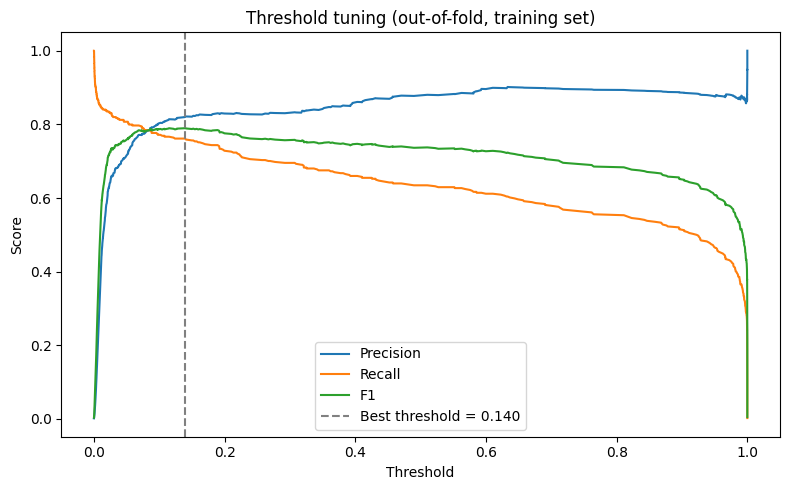

In [ ]:
# Out-of-fold probabilities on the training set, so the test set stays untouched
best_model = grid.best_estimator_
oof_proba = cross_val_predict(best_model, X_train_scaled, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train, oof_proba)
f1 = 2 * precision * recall / (precision + recall + 1e-12)
best_idx = np.argmax(f1[:-1])  # last PR point has no threshold
best_threshold = thresholds[best_idx]

print(f"Best threshold: {best_threshold:.4f}")
print(f"OOF at best threshold -> F1 {f1[best_idx]:.4f}, precision {precision[best_idx]:.4f}, recall {recall[best_idx]:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precision[:-1], label='Precision')
plt.plot(thresholds, recall[:-1], label='Recall')
plt.plot(thresholds, f1[:-1], label='F1')
plt.axvline(best_threshold, color='gray', linestyle='--', label=f'Best threshold = {best_threshold:.3f}')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Threshold tuning (out-of-fold, training set)')
plt.legend()
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

 Genuine (0)     0.9996    0.9995    0.9996     56864
   Fraud (1)     0.7282    0.7653    0.7463        98

    accuracy                         0.9991     56962
   macro avg     0.8639    0.8824    0.8729     56962
weighted avg     0.9991    0.9991    0.9991     56962



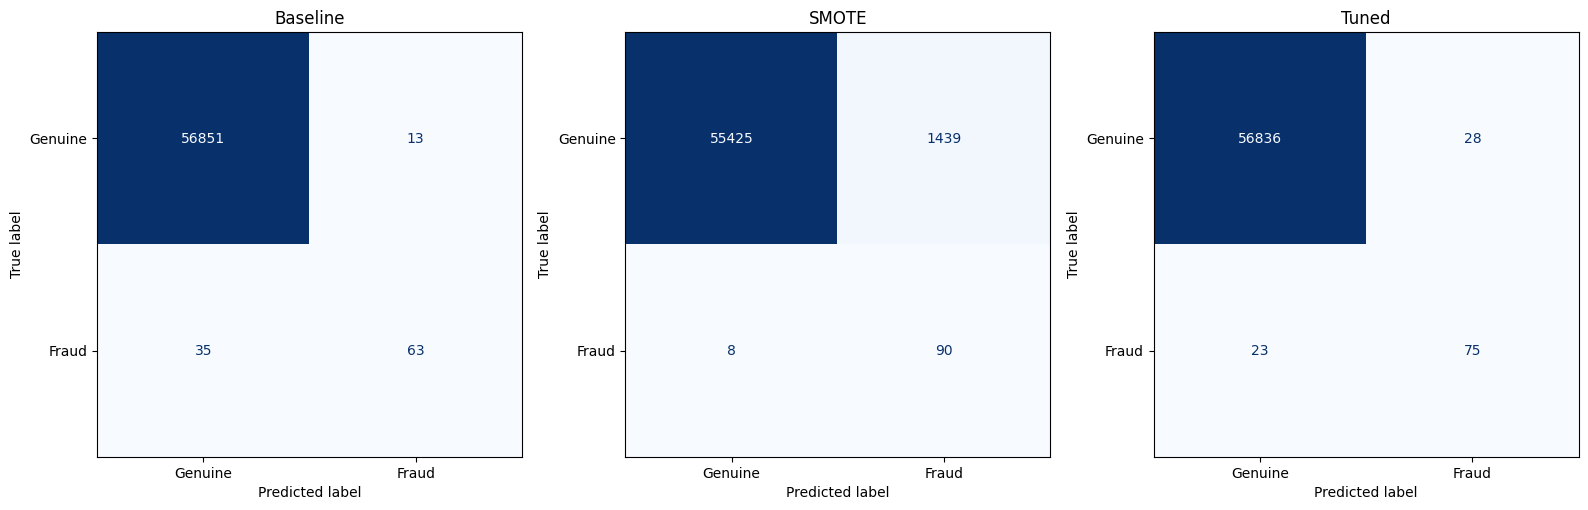

                   Baseline   SMOTE   Tuned
Precision (fraud)    0.8289  0.0589  0.7282
Recall (fraud)       0.6429  0.9184  0.7653
F1 (fraud)           0.7241  0.1106  0.7463
PR-AUC               0.7388  0.7251  0.7393


In [ ]:
# Final evaluation on the untouched test set
test_proba = best_model.predict_proba(X_test_scaled)[:, 1]
y_pred_tuned = (test_proba >= best_threshold).astype(int)

print(classification_report(y_test, y_pred_tuned, target_names=['Genuine (0)', 'Fraud (1)'], digits=4))

cm_tuned = confusion_matrix(y_test, y_pred_tuned)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, m, title in zip(axes, [cm, cm_smote, cm_tuned], ['Baseline', 'SMOTE', 'Tuned']):
    ConfusionMatrixDisplay(m, display_labels=['Genuine', 'Fraud']).plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
    ax.set_title(title)
plt.tight_layout()
plt.show()

def summarize(pred, proba):
    return [precision_score(y_test, pred), recall_score(y_test, pred), f1_score(y_test, pred), average_precision_score(y_test, proba)]

final_comparison = pd.DataFrame({
    'Baseline': summarize(y_pred, log_reg.predict_proba(X_test_scaled)[:, 1]),
    'SMOTE': summarize(y_pred_smote, log_reg_smote.predict_proba(X_test_scaled)[:, 1]),
    'Tuned': summarize(y_pred_tuned, test_proba),
}, index=['Precision (fraud)', 'Recall (fraud)', 'F1 (fraud)', 'PR-AUC'])
print(final_comparison.round(4))

We doin better now, this shows that the tuning works.
1. Best C setting is 0.1
2. But C barely mattered, every value scored between 0.759 and 0.762
3. SMOTE scored lower than no SMOTE at every C, SMOTE doesnt do much for logistic regression
4. Best threshold is 0.14, instead of the default 0.5
5. False alarms rose but still low
6. Now we bringin the big guns

## Random Forest and XGBoost

Same setup as logistic regression: same training set, same 5-fold `cv`, test set stays locked.

1. Sampling check per model (SMOTE vs none; XGBoost also tries `scale_pos_weight`), scored by PR-AUC.
2. Small grid search on the winning sampling option.
3. Threshold tuning by F1 on out-of-fold probabilities.
4. Compare all three models on out-of-fold results.
5. Run only the best model on the test set, once.

In [ ]:
# Helpers shared by all models

def show_cv(search):
    """Print mean/std CV PR-AUC for every setting tried."""
    res = pd.DataFrame(search.cv_results_)
    res['params'] = res['params'].astype(str)
    print(res[['params', 'mean_test_score', 'std_test_score']]
          .sort_values('mean_test_score', ascending=False)
          .round(4).to_string(index=False))
    print("Best:", search.best_params_, "| PR-AUC:", round(search.best_score_, 4))

def tune_threshold(y_true, proba):
    """Loop over thresholds, return the one with the best F1."""
    thresholds = np.linspace(0.01, 0.99, 99)
    f1s = [f1_score(y_true, (proba >= t).astype(int)) for t in thresholds]
    t = thresholds[int(np.argmax(f1s))]
    pred = (proba >= t).astype(int)
    return t, precision_score(y_true, pred), recall_score(y_true, pred), f1_score(y_true, pred)

oof_results, oof_probas, final_models = {}, {}, {}

def record(name, model, proba, params):
    t, p, r, f = tune_threshold(y_train, proba)
    oof_results[name] = {'PR-AUC': average_precision_score(y_train, proba),
                         'Precision': p, 'Recall': r, 'F1': f,
                         'Best threshold': t, 'Params': str(params)}
    oof_probas[name] = proba
    final_models[name] = model
    print(f"{name}: threshold {t:.2f} -> F1 {f:.4f}, precision {p:.4f}, recall {r:.4f}")

# Logistic regression, already tuned above
record('Logistic regression', best_model, oof_proba, grid.best_params_)

Logistic regression: threshold 0.13 -> F1 0.7895, precision 0.8197, recall 0.7614


### Random Forest

In [ ]:
# Colab CPU only has 2 cores, so RF is tuned on a subsample:
# all fraud rows + 20% of genuine rows, with 3-fold cv.
# The final out-of-fold comparison still uses the full training set and the same 5-fold cv.
fraud_idx = y_train[y_train == 1].index
genuine_idx = y_train[y_train == 0].sample(frac=0.2, random_state=42).index
sub_idx = fraud_idx.union(genuine_idx)
X_sub, y_sub = X_train_scaled.loc[sub_idx], y_train.loc[sub_idx]
print("Tuning subsample:", y_sub.value_counts().to_dict())

cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 1. Sampling check: SMOTE vs none, default-ish RF
# max_samples=0.3 -> each tree sees 30% of rows, much faster
start = time.time()
rf_pipe = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('clf', RandomForestClassifier(n_estimators=100, max_depth=12, max_samples=0.3,
                                   n_jobs=-1, random_state=42)),
])
rf_check = GridSearchCV(rf_pipe, {'smote': [SMOTE(random_state=42), 'passthrough']},
                        scoring='average_precision', cv=cv3, n_jobs=1, refit=False)
rf_check.fit(X_sub, y_sub)
show_cv(rf_check)
rf_sampler = rf_check.best_params_['smote']
print(f"Took {time.time() - start:.0f}s")

Tuning subsample: {0: 45490, 1: 394}
                           params  mean_test_score  std_test_score
{'smote': SMOTE(random_state=42)}           0.8759          0.0246
         {'smote': 'passthrough'}           0.8586          0.0117
Best: {'smote': SMOTE(random_state=42)} | PR-AUC: 0.8759
Took 49s


In [ ]:
# 2. Tune n_estimators and max_depth on the subsample, with the winning sampling option
start = time.time()
rf_grid = GridSearchCV(rf_pipe.set_params(smote=rf_sampler),
                       {'clf__n_estimators': [100, 200], 'clf__max_depth': [8, 16]},
                       scoring='average_precision', cv=cv3, n_jobs=1, refit=False)
rf_grid.fit(X_sub, y_sub)
show_cv(rf_grid)
print(f"Grid took {time.time() - start:.0f}s")

# 3. Out-of-fold probabilities on the FULL training set (same 5-fold cv as the other models)
start = time.time()
rf_best = rf_pipe.set_params(**rf_grid.best_params_)
rf_oof = cross_val_predict(rf_best, X_train_scaled, y_train, cv=cv, method='predict_proba')[:, 1]
rf_best.fit(X_train_scaled, y_train)  # final fit for the test set later
record('Random forest', rf_best, rf_oof, {'sampling': str(rf_sampler), **rf_grid.best_params_})
print(f"OOF + final fit took {time.time() - start:.0f}s")

                                          params  mean_test_score  std_test_score
{'clf__max_depth': 16, 'clf__n_estimators': 200}           0.8823          0.0173
{'clf__max_depth': 16, 'clf__n_estimators': 100}           0.8796          0.0222
 {'clf__max_depth': 8, 'clf__n_estimators': 200}           0.8693          0.0160
 {'clf__max_depth': 8, 'clf__n_estimators': 100}           0.8684          0.0148
Best: {'clf__max_depth': 16, 'clf__n_estimators': 200} | PR-AUC: 0.8823
Grid took 170s
Random forest: threshold 0.76 -> F1 0.8304, precision 0.8921, recall 0.7766
OOF + final fit took 1166s


### XGBoost

In [ ]:
# Use the GPU if the runtime has one
try:
    XGBClassifier(device='cuda', n_estimators=1).fit(np.random.rand(20, 2), np.tile([0, 1], 10))
    XGB_DEVICE = 'cuda'
except Exception:
    XGB_DEVICE = 'cpu'
print("XGBoost device:", XGB_DEVICE)

spw = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {spw:.1f}")

# 1. Sampling check: none vs SMOTE vs scale_pos_weight
start = time.time()
xgb_pipe = Pipeline([
    ('smote', 'passthrough'),
    ('clf', XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, tree_method='hist',
                          device=XGB_DEVICE, eval_metric='aucpr', random_state=42, verbosity=0)),
])
xgb_check = GridSearchCV(xgb_pipe, [
    {'smote': ['passthrough', SMOTE(random_state=42)], 'clf__scale_pos_weight': [1]},
    {'smote': ['passthrough'], 'clf__scale_pos_weight': [spw]},
], scoring='average_precision', cv=cv, n_jobs=1)
xgb_check.fit(X_train_scaled, y_train)
show_cv(xgb_check)
xgb_sampling = {k: v for k, v in xgb_check.best_params_.items()}
print(f"Took {time.time() - start:.0f}s")

XGBoost device: cuda
scale_pos_weight = 577.3
                                                                          params  mean_test_score  std_test_score
{'clf__scale_pos_weight': np.float64(577.2868020304569), 'smote': 'passthrough'}           0.8465          0.0150
                   {'clf__scale_pos_weight': 1, 'smote': SMOTE(random_state=42)}           0.8393          0.0285
                            {'clf__scale_pos_weight': 1, 'smote': 'passthrough'}           0.8320          0.0171
Best: {'clf__scale_pos_weight': np.float64(577.2868020304569), 'smote': 'passthrough'} | PR-AUC: 0.8465
Took 38s


In [ ]:
# 2. Tune n_estimators, max_depth, learning_rate with the winning sampling option
start = time.time()
xgb_grid = GridSearchCV(xgb_pipe.set_params(**xgb_sampling), {
    'clf__n_estimators': [200, 400],
    'clf__max_depth': [4, 6],
    'clf__learning_rate': [0.05, 0.1],
}, scoring='average_precision', cv=cv, n_jobs=1)
xgb_grid.fit(X_train_scaled, y_train)
show_cv(xgb_grid)

# 3. Out-of-fold probabilities + threshold tuning
xgb_best = xgb_grid.best_estimator_
xgb_oof = cross_val_predict(xgb_best, X_train_scaled, y_train, cv=cv, method='predict_proba')[:, 1]
record('XGBoost', xgb_best, xgb_oof, {**{k: str(v) for k, v in xgb_sampling.items()}, **xgb_grid.best_params_})
print(f"Took {time.time() - start:.0f}s")

                                                                     params  mean_test_score  std_test_score
 {'clf__learning_rate': 0.1, 'clf__max_depth': 6, 'clf__n_estimators': 400}           0.8470          0.0133
 {'clf__learning_rate': 0.1, 'clf__max_depth': 6, 'clf__n_estimators': 200}           0.8466          0.0191
{'clf__learning_rate': 0.05, 'clf__max_depth': 6, 'clf__n_estimators': 400}           0.8465          0.0199
 {'clf__learning_rate': 0.1, 'clf__max_depth': 4, 'clf__n_estimators': 400}           0.8452          0.0175
 {'clf__learning_rate': 0.1, 'clf__max_depth': 4, 'clf__n_estimators': 200}           0.8365          0.0132
{'clf__learning_rate': 0.05, 'clf__max_depth': 4, 'clf__n_estimators': 400}           0.8333          0.0111
{'clf__learning_rate': 0.05, 'clf__max_depth': 6, 'clf__n_estimators': 200}           0.8300          0.0200
{'clf__learning_rate': 0.05, 'clf__max_depth': 4, 'clf__n_estimators': 200}           0.8003          0.0267
Best: {'clf__learni

### Comparison (out-of-fold, training set)

                     PR-AUC  Precision  Recall      F1  Best threshold
Logistic regression  0.7585     0.8197  0.7614  0.7895            0.13
Random forest        0.8292     0.8921  0.7766  0.8304            0.76
XGBoost              0.8451     0.9458  0.7970  0.8650            0.76

Logistic regression: {'clf__C': 0.1, 'smote': 'passthrough'}
Random forest: {'sampling': 'SMOTE(random_state=42)', 'clf__max_depth': 16, 'clf__n_estimators': 200}
XGBoost: {'clf__scale_pos_weight': '577.2868020304569', 'smote': 'passthrough', 'clf__learning_rate': 0.1, 'clf__max_depth': 6, 'clf__n_estimators': 400}


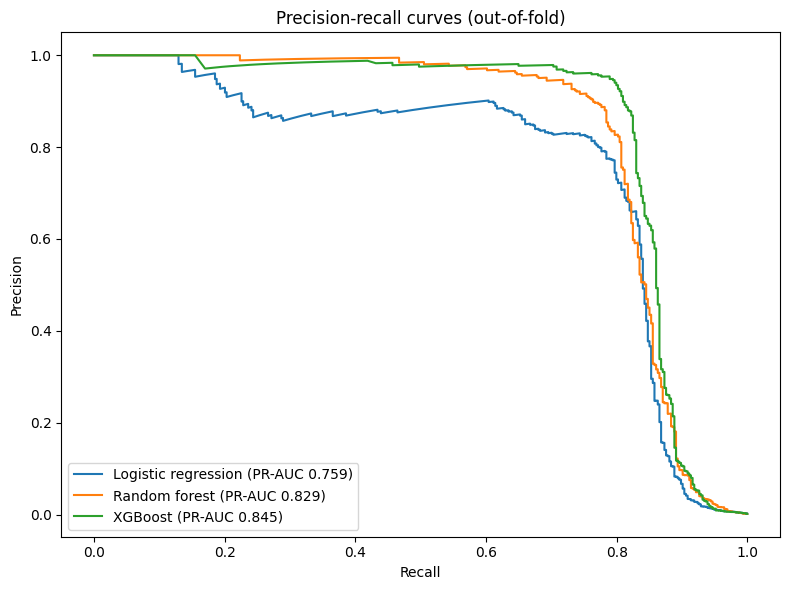

In [ ]:
comparison_all = pd.DataFrame(oof_results).T
print(comparison_all.drop(columns='Params').astype(float).round(4))
print()
for name, row in comparison_all.iterrows():
    print(f"{name}: {row['Params']}")

plt.figure(figsize=(8, 6))
for name, proba in oof_probas.items():
    p, r, _ = precision_recall_curve(y_train, proba)
    plt.plot(r, p, label=f"{name} (PR-AUC {average_precision_score(y_train, proba):.3f})")
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-recall curves (out-of-fold)')
plt.legend()
plt.tight_layout()
plt.show()

### Final Test (best model only, run once)

Best model: XGBoost (threshold 0.76)
Test PR-AUC: 0.8851
              precision    recall  f1-score   support

 Genuine (0)     0.9997    0.9998    0.9998     56864
   Fraud (1)     0.9011    0.8367    0.8677        98

    accuracy                         0.9996     56962
   macro avg     0.9504    0.9183    0.9338     56962
weighted avg     0.9995    0.9996    0.9996     56962



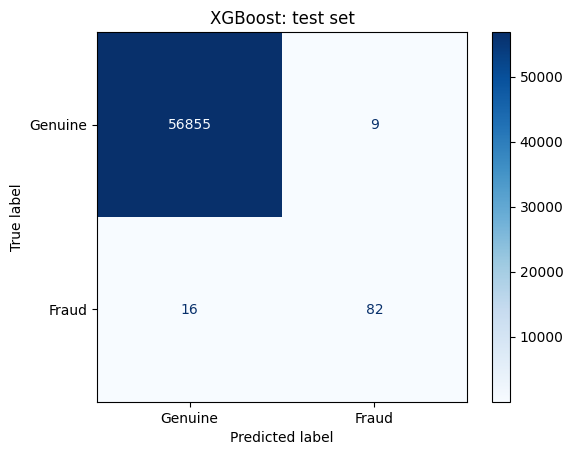

In [ ]:
# Best model = highest out-of-fold PR-AUC
best_name = comparison_all['PR-AUC'].astype(float).idxmax()
final_model = final_models[best_name]
final_threshold = float(comparison_all.loc[best_name, 'Best threshold'])
print(f"Best model: {best_name} (threshold {final_threshold:.2f})")

final_proba = final_model.predict_proba(X_test_scaled)[:, 1]
y_pred_final = (final_proba >= final_threshold).astype(int)

print("Test PR-AUC:", round(average_precision_score(y_test, final_proba), 4))
print(classification_report(y_test, y_pred_final, target_names=['Genuine (0)', 'Fraud (1)'], digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_final), display_labels=['Genuine', 'Fraud']).plot(cmap='Blues', values_format='d')
plt.title(f'{best_name}: test set')
plt.show()

## Findings

| Model | PR-AUC | Precision | Recall | F1 |
|---|---|---|---|---|
| Logistic regression | 0.759 | 0.820 | 0.761 | 0.790 |
| Random forest | 0.829 | 0.892 | 0.777 | 0.830 |
| XGBoost | 0.845 | 0.946 | 0.797 | 0.865 |

- XGBoost wins on every metric!
- Test set: PR-AUC 0.885, caught 82 of 98 frauds (recall 0.84), only 9 false alarms out of 56,864 genuine (precision 0.90)
- Tree models beat logistic regression by a lot
- Best imbalance fix depends on the model: SMOTE helped RF, scale_pos_weight worked best for XGBoost, LR did best with neither
- Default threshold 0.5 is wrong for all of them. Trees like 0.76 & LR likes 0.13
- RF was tuned on a subsample (all fraud + 20% genuine, 3-fold) because Colab CPU only has 2 cores. XGBoost on GPU took ~2 min, RF took ~23 min